# Energy and losses through a staged outer loop

Each outer step **trains the NQS, samples a Ritz basis, updates angles, teaches the NQS, continues VMC, and accepts or restores the proposal**. Lower physical NQS energy is the only criterion for improvement. The network represents coefficients $|\phi_w\rangle$ in the current basis. Its physical state is $U_\theta|\phi_w\rangle$ with energy $E_{\rm NQS}=\langle\phi_w|U_\theta^\dagger H U_\theta|\phi_w\rangle$. During angle updates **the NQS parameters $w$ stay unchanged**. The rotation loss uses the ground energy $E_{\rm Ritz}$ of a **finite sampled space**, so its decrease need not lower $E_{\rm NQS}$ - this is samples dependent and should be monitored.

The schedule has three kinds of outer step: 
- a warm VMC stage without rotation, 
- rotation stages at a fixed target Ritz size, 
- and a final VMC polish at fixed accepted angles. 

Select the spin model with `SYSTEM` and the budget with `QUICK`. An optional spinful Hubbard section (*experimental*) at the end uses the fermionic orbital loop.

`N_SUBSPACE` sets the target size as an integer state count or a float fraction of the physical symmetry sector (for example, `0.25`). The resolved size is limited by the sector dimension. Keeping the size fixed controls matrix cost; energy convergence when increasing the target size and the number of outer stages is still needed to assess the basis.

In [1]:
%load_ext autoreload
%autoreload 3

from pathlib import Path
import dataclasses as dc
import math
import os
import sys
os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"

# Set the repo root to the parent of the current working directory if the current working directory is not the repo root
REPO_ROOT = Path.cwd().resolve()
if not (REPO_ROOT / "src").is_dir():
	REPO_ROOT = REPO_ROOT.parent
sys.path.insert(0, str(REPO_ROOT))

import 	jax
import 	numpy as np
import 	matplotlib.pyplot as plt

# Plotting and logging
from 	deps.general_plot.general_plot 	import Plotter
from 	src.logging_utils 				import log

# Adaptive loop
from 	src.adaptive 					import run_adaptive_loop
from 	src.config 						import AdaptiveConfig, AdaptiveStep, CircuitConfig, FinalConfig, LatticeConfig, ModelConfig, RotationConfig, TeacherConfig, TrainConfig

%matplotlib inline
jax.config.update("jax_enable_x64", True)
jax.config.update("jax_enable_compilation_cache", True)

∣NK⟩ Tip: nk.observable.VScore(H): V-score ≤ 1e-4 means your ansatz is very good; 0 is exact.

## Settings: model, optimizer, basis, and rotation cost

`SYSTEM` selects one of two square-lattice spin models, with $S^a=\sigma^a/2$.

- `"tfi"`: $H=-J\sum_{\langle ij\rangle}S_i^zS_j^z-h_x\sum_i S_i^x-h_z\sum_i S_i^z$. 
  - It is stoquastic in the $S^z$ basis, so its ground state is positive. 
  - The network is not told this: it keeps a learned complex phase, and positivity must be learned. 
  - The circuit uses real-orthogonal `XY` gates (*experiment with me*).
- `"j1j2"`: $H=J_1\sum_{\langle ij\rangle}\mathbf S_i\cdot\mathbf S_j+J_2\sum_{\langle\langle ij\rangle\rangle}\mathbf S_i\cdot\mathbf S_j$ at $J_2/J_1=0.5$. 
  - It is frustrated and has a sign problem. 
  - The NQS conserves total $S^z$ but has no Marshall reference phase, so the sign structure must be learned or found by the rotation. 
  - The circuit uses $S^z$-conserving `givens` gates (*experiment with me*)

### Quick settings 

`QUICK=True` uses open lattices with exact diagnostics: 3 x 3 for TFI and 4 x 2 for J1-J2. `QUICK=False` uses periodic 4 x 4 lattices with Monte Carlo diagnostics and an exact reference energy.

### Optimizer and learning rate

**NQS optimizer.** Training uses minSR with SPRING momentum 0.8 and an SR diagonal shift that decays by cosine from $10^{-2}$ to $10^{-4}$ in every VMC block (*experiment with me*). The final polish stage also decays the learning rate.
**Rotation cost.** The energy term is $E_{\rm Ritz}/(NJ_{\rm rms})$. The added terms address what makes an autoregressive network hard to train:

- `entanglement_weight` penalizes the summed cut Rényi-2 entropy of the Ritz target **along the autoregressive site order** (*experiment with me*). This is the order in which the conditionals must carry correlations!
- `nonstoquasticity_weight` penalizes positive off-diagonal weight of the projected Hamiltonian . For J1-J2 this targets the sign structure. For TFI it is a guard: the unrotated Hamiltonian is stoquastic, and an unpenalized rotation can destroy that.
- `participation_weight` is off by default. For a pure state every cut satisfies $S_2(\rho_A)\le-\log\sum_i|v_i|^4$, so participation bounds all cuts at once but over-constrains towards a single configuration - TODO: how to define this better and use it to shrink the necessary basis (so that the sampling is easier)?

All terms are selected-state proxies on the sampled support. None is a proven predictor of trainability; the controls below compare physical NQS energies. The earlier 3 x 3 Ising audit found that rotation increased VMC cost without beating continued VMC. TFI is therefore the control case, and J1-J2 is where a sign-aware basis can plausibly help.

In [2]:
# "tfi" or "j1j2"
SYSTEM				    = "j1j2"
QUICK				    = False
LX                      = 4
LY                      = 4 if not QUICK else 2
SEED				    = 0
N_WARM				    = 250 if QUICK else 400	    # VMC updates before the first rotation
N_ROTATE			    = 5						    # outer rotation stages; increase to check convergence
N_POLISH			    = 150 if QUICK else 300	    # final fixed-basis VMC updates
N_SUBSPACE			    = 128 if QUICK else 2**8	# target Ritz size: integer states or float fraction of the physical sector
PARTICIPATION_WEIGHT    = 0.05					    # participation penalty in the rotation cost; 0 disables it
OUTPUT_DIR			    = REPO_ROOT / "runs" / f"{SYSTEM}_outer_{'quick' if QUICK else 'full'}"

if SYSTEM == "tfi":
    lattice		        = LatticeConfig(hamiltonian="ising", Lx=LX, Ly=LY if QUICK else 4, pbc=not QUICK, j1=1.0, hx=0.7, hz=0.03)
    model		        = ModelConfig(width=16 if QUICK else 24, depth=2, heads=4, mlp_ratio=2, conserve_total_sz=False)
    # Simple 2-layer XY circuit to be optimized...
    circuit		        = CircuitConfig(n_layers=2, family=("XY",), parameterization="gate")
    weights		        = dict(entanglement_weight=0.02, nonstoquasticity_weight=0.1)
    sector		        = 2 ** lattice.n_sites  # Particle number is not conserved, so the sector is the full Hilbert space.
elif SYSTEM == "j1j2":
    lattice		        = LatticeConfig(hamiltonian="j1j2", Lx=LX, Ly=LY, pbc=not QUICK, j1=1.0, j2=0.5)
    model		        = ModelConfig(width=16 if QUICK else 32, depth=2 if QUICK else 2, heads=4, mlp_ratio=2, phase_head_depth=1 if QUICK else 2, conserve_total_sz=True)
    # Apply only givens rotations to the 2-layer circuit, so that the NQS can learn the sign structure of the frustrated J1-J2 model
    circuit		        = CircuitConfig(n_layers=2, family=("givens",), parameterization="gate")
    weights		        = dict(entanglement_weight=0.02, nonstoquasticity_weight=0.1)
    sector		        = math.comb(lattice.n_sites, lattice.n_sites // 2)
else:
    raise ValueError("SYSTEM must be 'tfi' or 'j1j2'")

# minSR + SPRING; the SR shift decays inside every VMC block.
train		= TrainConfig(n_nqs=100 if QUICK else 300, learning_rate=0.02, use_sr=True, sr_shift=1e-2, sr_shift_final=1e-4, sr_schedule="cosine", sr_momentum=0.8)
if type(N_SUBSPACE) is int and N_SUBSPACE >= 2:
    n_subspace = min(sector, N_SUBSPACE)
elif type(N_SUBSPACE) is float and 0.0 < N_SUBSPACE <= 1.0:
    n_subspace = min(sector, max(2, math.ceil(N_SUBSPACE * sector)))
else:
    raise ValueError("N_SUBSPACE must be an integer >= 2 or a float fraction in (0, 1]")
if type(N_ROTATE) is not int or N_ROTATE < 1:
    raise ValueError("N_ROTATE must be a positive integer")
rotation	= RotationConfig(n_rot=50 if QUICK else 150, n_subspace=n_subspace, learning_rate=0.003, nqs_energy_every=5 if QUICK else 25, **weights)
teacher		= TeacherConfig(n_teacher=50 if QUICK else 200, learning_rate=0.001, phase_weight=0.5, nqs_energy_every=10 if QUICK else 50)
step		= AdaptiveStep(train=train, rotation=rotation, teacher=teacher, n_recovery=30 if QUICK else 100)

# Schedule: warm VMC, rotation stages at fixed Ritz size, then polish
def staged(rotate: AdaptiveStep) -> tuple[AdaptiveStep, ...]:
    """Keep the target Ritz size fixed through warm, rotation, and polish stages."""
    frozen	= dict(rotation=dc.replace(rotate.rotation, n_rot=0), teacher=dc.replace(rotate.teacher, n_teacher=0), n_recovery=0)
    warm	= dc.replace(rotate, train=dc.replace(rotate.train, n_nqs=N_WARM), **frozen)
    polish	= dc.replace(rotate, train=dc.replace(rotate.train, n_nqs=N_POLISH, learning_rate_final=0.002, learning_rate_schedule="cosine"), **frozen)
    return (warm, *((rotate,) * N_ROTATE), polish)


schedule	= staged(step)
N_OUTER		= len(schedule)
adaptive	= AdaptiveConfig(circuit=circuit, steps=schedule, final=FinalConfig(), display="plain")
figure_dir	= OUTPUT_DIR / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)

def values(rows, name):
    return np.asarray([row[name] for row in rows], dtype=float)

def show_figure(fig, name):
    fig.tight_layout()
    for extension in ("png", "pdf"):
        Plotter.savefig(str(figure_dir), f"{name}.{extension}", format=extension, adjust=False, fig=fig)
    plt.show()

log(f"{SYSTEM} | {lattice.Lx}x{lattice.Ly} | PBC={lattice.pbc} | sector {sector} | {jax.default_backend()} | {train.n_samples} VMC samples")
log(f"Schedule: warm {N_WARM} VMC | {N_ROTATE} rotation stages | fixed Ritz size {n_subspace} | polish {N_POLISH} VMC")
for i, stage in enumerate(schedule):
    log(f"Outer {i + 1}: {stage.train.n_nqs} NQS + {stage.rotation.n_rot} angle + {stage.teacher.n_teacher} teacher + {stage.n_recovery} VMC | Ritz {stage.rotation.n_subspace} states, {stage.rotation.n_seed_samples} Born draws", level=2)
log(f"Rotation cost weights: {weights}")

[INFO] 	->j1j2 | 4x4 | PBC=True | sector 12870 | cpu | 256 VMC samples
[INFO] 	->Schedule: warm 400 VMC | 5 rotation stages | fixed Ritz size 256 | polish 300 VMC
[INFO] 		->Outer 1: 400 NQS + 0 angle + 0 teacher + 0 VMC | Ritz 256 states, 8192 Born draws
[INFO] 		->Outer 2: 300 NQS + 150 angle + 200 teacher + 100 VMC | Ritz 256 states, 8192 Born draws
[INFO] 		->Outer 3: 300 NQS + 150 angle + 200 teacher + 100 VMC | Ritz 256 states, 8192 Born draws
[INFO] 		->Outer 4: 300 NQS + 150 angle + 200 teacher + 100 VMC | Ritz 256 states, 8192 Born draws
[INFO] 		->Outer 5: 300 NQS + 150 angle + 200 teacher + 100 VMC | Ritz 256 states, 8192 Born draws
[INFO] 		->Outer 6: 300 NQS + 150 angle + 200 teacher + 100 VMC | Ritz 256 states, 8192 Born draws
[INFO] 		->Outer 7: 300 NQS + 0 angle + 0 teacher + 0 VMC | Ritz 256 states, 8192 Born draws
[INFO] 	->Rotation cost weights: {'entanglement_weight': 0.02, 'nonstoquasticity_weight': 0.1}


## Run the staged outer loop

This is the repository's adaptive loop with the model-specific cost. The log reports physical energies at stage boundaries, sample coverage, accepted or rejected proposals, and timings. Energy observations during rotation precede any NQS adjustment. Teacher observations use the updated NQS at fixed angles. Warm and polish stages have no rotation or teacher segment.

In [3]:
result  = run_adaptive_loop(lattice, model, adaptive, seed=SEED, output_dir=OUTPUT_DIR / "recommended")
outer   = result["outer_history"]
E0      = result["exact_energy"]
N       = lattice.n_sites


def energy_per_site(energy, n_sites=N, reference=E0):
    """Return energy per site, relative to the exact ground state when available."""
    energy = np.asarray(energy) / n_sites
    return energy if reference is None else energy - reference / n_sites


[INFO] ===========================Adaptive-basis NQS===========================
[INFO] 	->Model: j1j2 | 4x4 | N=16 | PBC=True | seed=0
[INFO] 	->Device: cpu:0 | JAX x64=True
[INFO] 	->ARTransformer: width=32, depth=2, heads=4, mlp_ratio=2, conserve_total_sz=True
[INFO] 	->Exact ground energy: -8.457923351395 (E/N: -0.528620209462) | 0.637 s
[INFO] 	->Adaptive loop: 7 steps, 16 fixed circuit gates, 16 trainable parameters
[INFO] =============================Outer step 1/7=============================
[INFO] 	->Train NQS (400 updates) | started
[INFO] 		->[NQS] fresh init | |theta|=0.000000 | 16 gates
[INFO] 			->Hamiltonian: 192 base -> 11216 rotated -> 192 pruned terms | max connections=65
[INFO] 			->Build timings: basis=0.029 s | NetKet operator=0.003 s
[INFO] 		->NQS: minSR:sgd(mode=complex, shift=1.0e-02->1.0e-04/cosine) SPRING(0.8) | lr=0.02 | 400 updates | 256 MC samples | chunk=128


  0%|          | 0/400 [00:00<?, ?it/s]

Stopped by user.
[INFO] 		->NQS: completed 274/400 updates in 132.779 s (setup and compilation included)
[INFO] 		->[NQS] MC tail mean (pre-update observations): E=-7.293486349 | E/N=-0.455842897 | variance=0.180336
[INFO] 	->Train NQS (400 updates) | finished in 132.815 s
[INFO] 			->[Evaluate NQS] independent MC: 256 samples | E=-7.279800696 | variance=0.0666623 | SE=0.0157 | 0.550 s
[INFO] 	->Before rotation: E=-7.279800696499 | E/N=-0.454987543531
[INFO] 		->independent MC | variance=0.0666623 | SE=0.0157 | 0.551 s
[INFO] 		->E-E0=+1.17812
[INFO] 		->Seed sampling (frequency): 256 ranked seed candidates from 8192 Born draws
[INFO] 			->subspace assembled: 256 states total (0 retained + 256 seeds & connected)
[INFO] 	->Select Ritz basis: 256/256 states | NQS mass=0.844489 | 2.908 s
[INFO] 		->SQD sampling: method=frequency | Born draws=8192/8192 | unique Born states=545 | Gumbel draws=0
[INFO] 	->Rotate: 0 updates | NQS probe stride=25
[INFO] 		->Rotation weights: participation=0, e

  0%|          | 0/300 [00:00<?, ?it/s]

[INFO] 		->NQS: completed 300/300 updates in 140.706 s (setup and compilation included)
[INFO] 		->[NQS] MC tail mean (pre-update observations): E=-7.291306344 | E/N=-0.455706646 | variance=0.0261775
[INFO] 	->Train NQS (300 updates) | finished in 140.738 s
[INFO] 			->[Evaluate NQS] independent MC: 256 samples | E=-7.294531630 | variance=0.00246261 | SE=0.00275 | 0.515 s
[INFO] 	->Before rotation: E=-7.294531630053 | E/N=-0.455908226878
[INFO] 		->independent MC | variance=0.00246261 | SE=0.00275 | 0.516 s
[INFO] 		->E-E0=+1.16339
[INFO] 		->Subspace retention: kept top 25/256 states from previous Ritz basis (f_retain=0.10)
[INFO] 		->Seed sampling (frequency): 256 ranked seed candidates from 8192 Born draws
[INFO] 			->subspace assembled: 256 states total (25 retained + 231 seeds & connected)
[INFO] 	->Select Ritz basis: 256/256 states | NQS mass=0.841869 | 0.575 s
[INFO] 		->SQD sampling: method=frequency | Born draws=8192/8192 | unique Born states=550 | Gumbel draws=0
[INFO] 	->Rot

...

[INFO] 			->[Evaluate NQS] independent MC: 256 samples | E=-8.035701770 | variance=0.199792 | SE=0.0289 | 3.547 s
[INFO] 		->Teacher probe 50/200: NQS E=-8.035701770 | SE=0.0289
[INFO] 			->[Evaluate NQS] independent MC: 256 samples | E=-8.033298094 | variance=0.597968 | SE=0.0477 | 3.851 s
[INFO] 		->Teacher probe 100/200: NQS E=-8.033298094 | SE=0.0477
[INFO] 			->[Evaluate NQS] independent MC: 256 samples | E=-8.081914214 | variance=0.47625 | SE=0.042 | 3.696 s
[INFO] 		->Teacher probe 150/200: NQS E=-8.081914214 | SE=0.042
[INFO] 		->Teacher loss=0.00516913 | joint KL/site=0.00413542 | conditional KL/site=0.00266147 | mass loss/site=0.00147396
[INFO] 		->Subspace mass=0.976693 | phase coherence=0.997933 | phase loss=0.00103371 | 3.101 s
[INFO] 		->NQS fidelity with Ritz target=0.962324 (squared full-state overlap)
[INFO] 		->Teacher objective evaluations=201 (includes line search and final evaluation)
[INFO] 			->[Evaluate NQS] independent MC: 256 samples | E=-8.062686037 | varianc

  0%|          | 0/100 [00:00<?, ?it/s]

Stopped by user.
[INFO] 		->VMC recovery: completed 2/100 updates in 11.080 s (setup and compilation included)
[INFO] 			->[Evaluate NQS] independent MC: 256 samples | E=-8.155247699 | variance=2.25094 | SE=0.096 | 3.762 s
[INFO] 	->After recovery: E=-8.155247699317 | E/N=-0.509702981207 | dE=-0.0925617
[INFO] 		->independent MC | variance=2.25094 | SE=0.096 | 3.763 s
[INFO] 		->E-E0=+0.302676
[INFO] 	->Proposal accepted: NQS dE=-0.0658298 | combined SE=0.0986 | acceptance threshold=0.197
[INFO] 		->Operator cost: terms 11216 -> 11216 | max connections 597 -> 597
[INFO] 		->VMC slowdown: unmeasured (need at least 4 updates in both training blocks)
[INFO] Outer 6: E_NQS=-8.155248 (E/N=-0.509703) Ritz=-8.127173 (E/N=-0.507948) +PT2=omitted
[INFO] 	->##################Outer 6 timing##################
[INFO] 		->|--------------------|----------------|
[INFO] 		->| Phase              |   Duration (s) |
[INFO] 		->|--------------------|----------------|
[INFO] 		->| Train NQS          |     

  0%|          | 0/300 [00:00<?, ?it/s]

Stopped by user.
[INFO] 		->NQS: completed 23/300 updates in 90.637 s (setup and compilation included)
[INFO] 		->[NQS] MC tail mean (pre-update observations): E=-8.026083067 | E/N=-0.501630192 | variance=0.406938
[INFO] 	->Train NQS (300 updates) | finished in 90.765 s
[INFO] 			->[Evaluate NQS] independent MC: 256 samples | E=-8.137950323 | variance=0.622056 | SE=0.0502 | 3.715 s
[INFO] 	->Before rotation: E=-8.137950323344 | E/N=-0.508621895209
[INFO] 		->independent MC | variance=0.622056 | SE=0.0502 | 3.716 s
[INFO] 		->E-E0=+0.319973
[INFO] 		->Subspace retention: kept top 25/256 states from previous Ritz basis (f_retain=0.10)
[INFO] 		->Seed sampling (frequency): 256 ranked seed candidates from 8192 Born draws
[INFO] 			->subspace assembled: 256 states total (25 retained + 231 seeds & connected)
[INFO] 	->Select Ritz basis: 256/256 states | NQS mass=0.982695 | 1.124 s
[INFO] 		->SQD sampling: method=frequency | Born draws=8192/8192 | unique Born states=305 | Gumbel draws=0
[INFO

## Does the NQS energy decrease through each outer step?

The horizontal coordinate counts completed optimizer updates within that outer step. Colors mark which parameters are being updated.

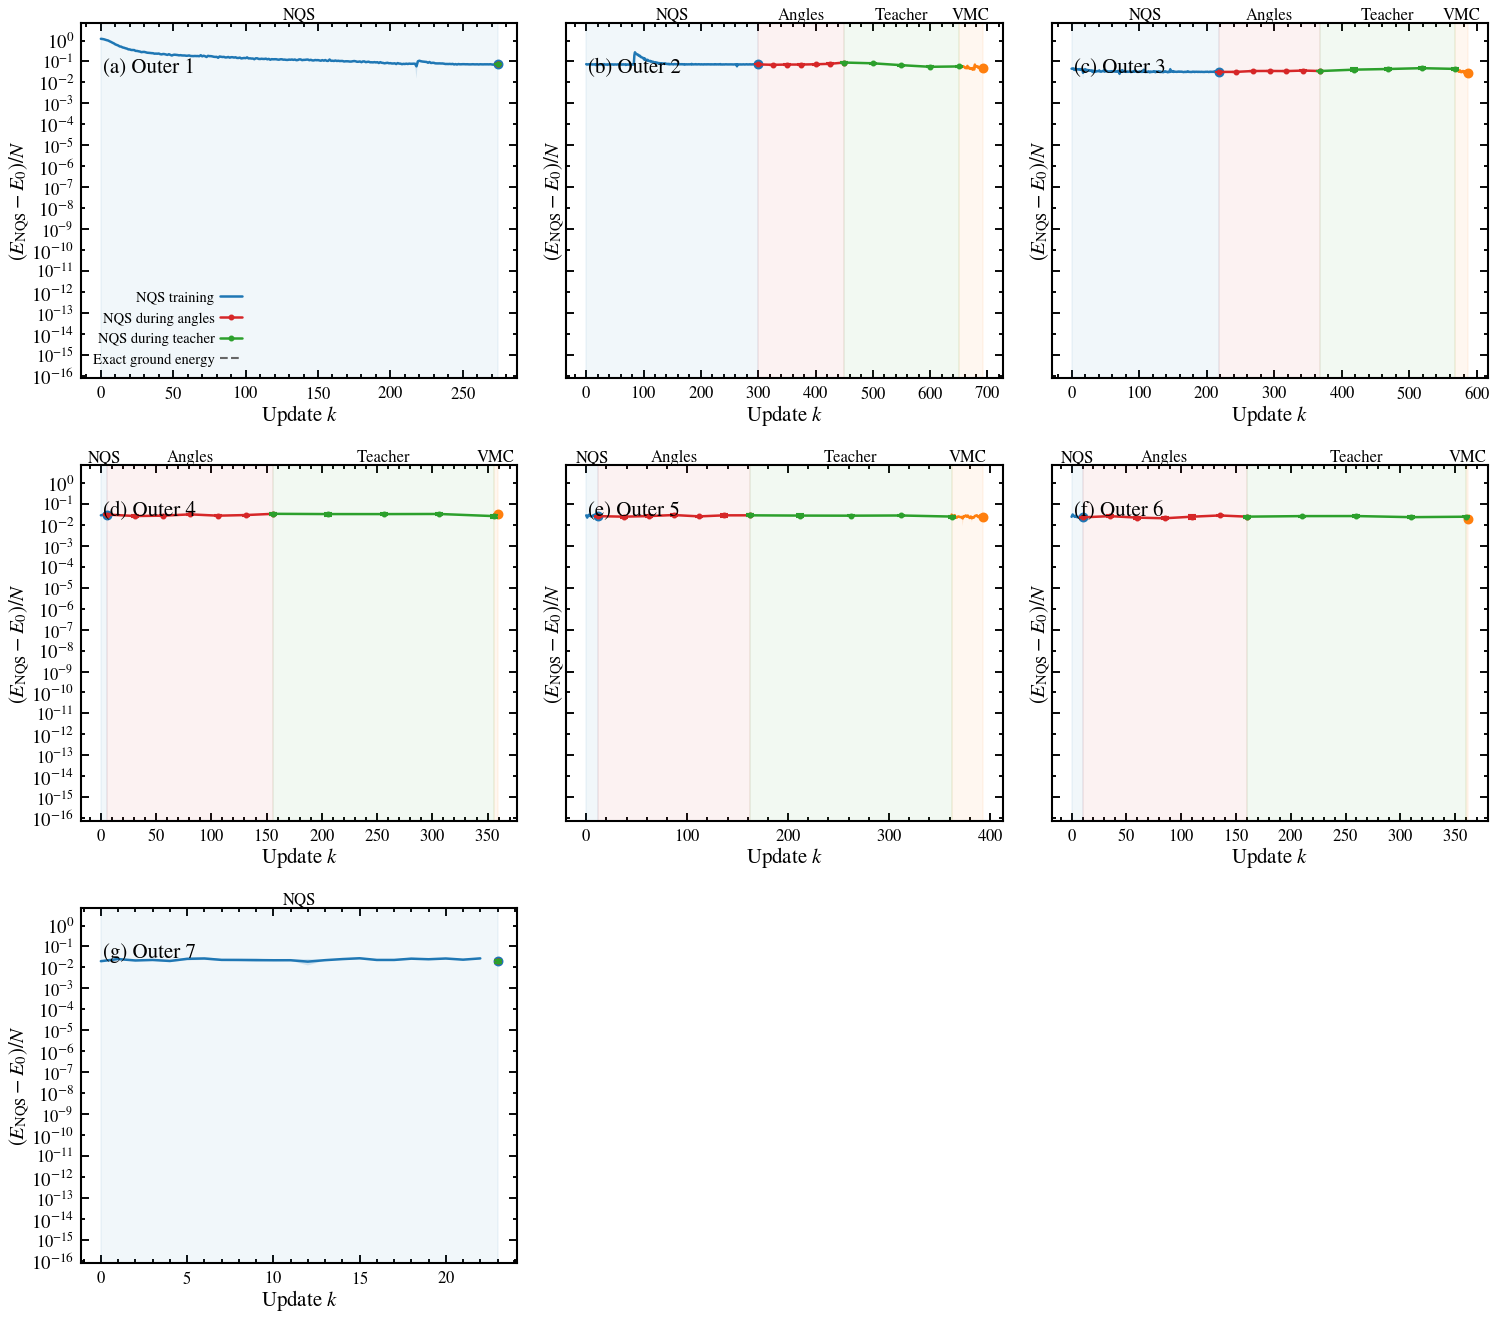

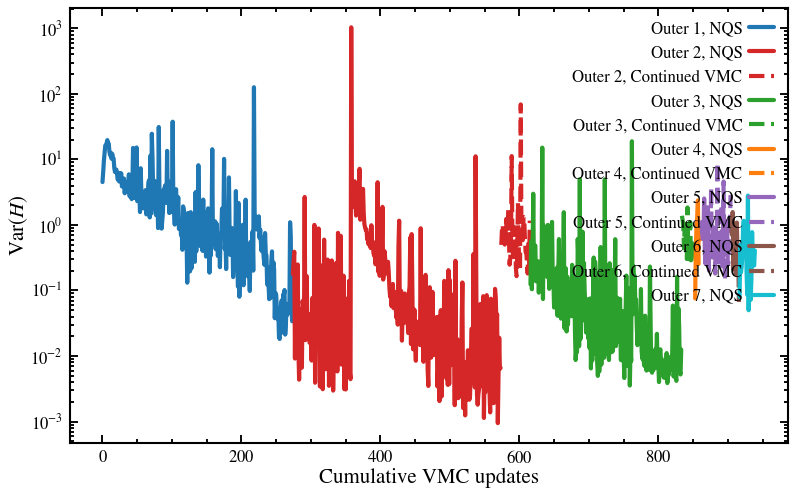

In [5]:
OUTER_STEPS = len(outer)
NCOLS       = min(3, OUTER_STEPS)
NROWS       = math.ceil(OUTER_STEPS / NCOLS)
fig, axes   = Plotter.get_subplots(NROWS, NCOLS, sizex=3.4 * NCOLS, sizey=3.0 * NROWS, constrained_layout=False, sharey=True)
axes        = np.atleast_1d(axes).ravel()
for ax in axes[OUTER_STEPS:]:
    ax.set_visible(False)

# Plot each outer step with phase spans, energy uncertainty, and phase endpoints.
for i, (ax, summary) in enumerate(zip(axes, outer)):
    nqs_rows        = [row for row in result["nqs_history"] if row["outer"] == i]
    recovery_rows   = [row for row in result["recovery_history"] if row["outer"] == i]

    n_train         = len(nqs_rows)
    n_angle         = adaptive.steps[i].rotation.n_rot
    n_teacher       = sum(row["outer"] == i for row in result["teacher_history"])
    n_recovery      = len(recovery_rows)
    start_angle, start_teacher, start_vmc = n_train, n_train + n_angle, n_train + n_angle + n_teacher
    phases = [(0, n_train, "NQS", "C0"), (start_angle, n_angle, "Angles", "C1"),
              (start_teacher, n_teacher, "Teacher", "C2"), (start_vmc, n_recovery, "VMC", "C3")]
    Plotter.phase_spans(ax, phases)

    for rows, start, label, color, endpoint in [
        (nqs_rows, 0, "NQS training", "C0", summary["energy_before_rotation"]),
        (recovery_rows, start_vmc, "Continued VMC", "C3", summary["energy_after_recovery"]),
    ]:
        if rows:
            x   = start + np.arange(len(rows))
            y   = energy_per_site(values(rows, "energy"))
            se  = values(rows, "standard_error") / N
            Plotter.plot_with_uncertainty(ax, x, y, se, color=color, alpha=0.15, lw=1.2, label=label)
            Plotter.plot(ax, [start + len(rows)], [energy_per_site(endpoint)], marker="o", color=color, ls="none", ms=4)

    for rows, start, label, color in [
        (summary["rotation_nqs_history"], start_angle, "NQS during angles", "C1"),
        (summary["teacher_nqs_history"], start_teacher, "NQS during teacher", "C2"),
    ]:
        if rows:
            x   = start + values(rows, "step")
            y   = energy_per_site(values(rows, "energy"))
            se  = values(rows, "standard_error") / N
            Plotter.plot(ax, x, y, color=color, marker=".", lw=1.2, label=label)
            Plotter.errorbar(ax, x, y, yerr=se, fmt="none", color=color, ecolor=color)

    if not summary["accepted"]:
        x = start_vmc + n_recovery + 2
        Plotter.plot(ax, [x], [energy_per_site(summary["energy"])], marker="x", ms=7,
                     color="black", ls="none", label="Restored after rejection")
    if E0 is not None:
        Plotter.hline(ax, 0, color="0.4", ls="--", lw=1, label="Exact ground energy")

    ylabel = r"$(E_{\rm NQS}-E_0)/N$" if E0 is not None else r"$E_{\rm NQS}/N$"
    Plotter.set_ax_params(ax, xlabel=r"Update $k$", ylabel=ylabel, yscale='linear' if E0 is None else 'log')
    Plotter.letter(ax, index=i, text=f"Outer {i + 1}", x=0.05, y=0.9)
    if i == 0:
        Plotter.set_legend(ax, frameon=False, fontsize=7, loc="best")

show_figure(fig, "nqs_energy_history")

fig, ax = Plotter.get_subplots(1, 1, sizex=5.5, sizey=3.5, constrained_layout=False)
offset = 0
for i in range(OUTER_STEPS):
    for name, label, ls in [("nqs_history", "NQS", "-"), ("recovery_history", "Continued VMC", "--")]:
        rows = [row for row in result[name] if row["outer"] == i]
        if rows:
            variance = np.maximum(values(rows, "variance"), 1e-12)
            Plotter.plot(ax, offset + np.arange(len(rows)), variance, color=f"C{i}", ls=ls,
                         label=f"Outer {i + 1}, {label}")
            offset += len(rows)
Plotter.set_ax_params(ax, xlabel="Cumulative VMC updates", ylabel=r"$\mathrm{Var}(H)$", yscale="log")

Plotter.set_legend(ax, frameon=False, fontsize=8)
show_figure(fig, "nqs_variance_history")


## Does rotation help before the teacher?

Compare the rotation loss and the two energies against angle-update history. $E_{\rm Ritz}$ is measured in the selected space, while $E_{\rm NQS}$ uses the unchanged network over its full support.

- A lower Ritz energy alongside a higher NQS energy is possible - changing $U_\theta$ with $w$ unchanged changes the physical state
- The current teacher fits the **new sampled Ritz state**
- Also, a truncated Ritz energy can exceed the full NQS energy because the latter has amplitudes outside the sampled space

The combination should be tested whether it makes sense.

/var/folders/7h/4tmv99_x2djdm97ys2h7mh5m0000gs/T/ipykernel_40694/910514464.py:64: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


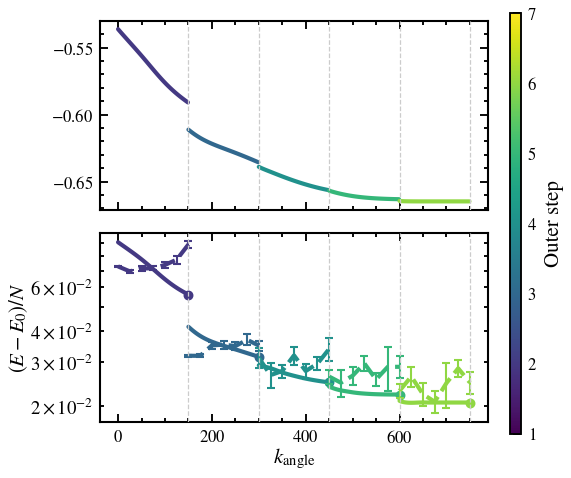

In [6]:
fig, axes   = Plotter.get_subplots(2, 1, sizex=OUTER_STEPS / 2, sizey=3.3, constrained_layout=False, sharex=True)
get_color   = Plotter.get_colormap(values=np.linspace(0, 1, OUTER_STEPS), cmap="viridis", vmin=0, vmax=OUTER_STEPS - 1)
offset      = 0
for i, summary in enumerate(outer):
    n_rot = adaptive.steps[i].rotation.n_rot
    if not n_rot:
        continue  # Warm and polish stages keep the angles fixed.

    rows            = [row for row in result["rotation_history"] if row["outer"] == i]
    trace           = summary["rotation_nqs_history"]
    color           = get_color(i)
    steps           = values(rows, "step") + offset
    ritz_energy     = energy_per_site(values(rows, "ritz_energy"))
    proposal_energy = energy_per_site(summary["proposal_ritz_energy"])
    nqs_energy      = energy_per_site(values(trace, "energy"))

    Plotter.plot(axes[0], steps, values(rows, "loss"), color=color, label=f"Outer {i + 1}")
    Plotter.plot(axes[1], steps, ritz_energy, color=color, label=f"Outer {i + 1}: Ritz")
    Plotter.plot(ax=axes[1], x=[offset + n_rot], y=[proposal_energy], color=color, marker="o", ls="none", ms=4)
    trace_steps = offset + values(trace, "step")
    Plotter.plot(axes[1], trace_steps, nqs_energy, color=color, ls="--", label=f"Outer {i + 1}: NQS before teacher")
    if len(trace):
        Plotter.errorbar(axes[1], trace_steps, nqs_energy, yerr=values(trace, "standard_error") / N, fmt="none", color=color, ecolor=color)

    offset += n_rot
    for ax in axes:
        Plotter.vline(ax, offset, color="0.8", lw=0.6)

Plotter.set_ax_params(axes[0])
Plotter.set_ax_params(axes[1], xlabel=r"$k_{\rm angle}$", ylabel=r"$(E-E_0)/N$" if E0 is not None else r"$E/N$", yscale='linear' if E0 is None else 'log')    
Plotter.add_colorbar(fig, pos=(1.0, 0.12, 0.02, 0.85), label="Outer step", ticks=np.arange(OUTER_STEPS), ticklabels=[f"{i + 1}" for i in range(OUTER_STEPS)], mappable=get_color)
show_figure(fig, "rotation_history")


## Does teaching improve the NQS in the new basis?

The teacher updates the existing NQS parameters at fixed angles. Plot its loss and the physical NQS energy against completed teacher updates. Lower teacher loss alone does not guarantee lower energy; the energy observations answer that question directly.

/var/folders/7h/4tmv99_x2djdm97ys2h7mh5m0000gs/T/ipykernel_40694/910514464.py:64: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


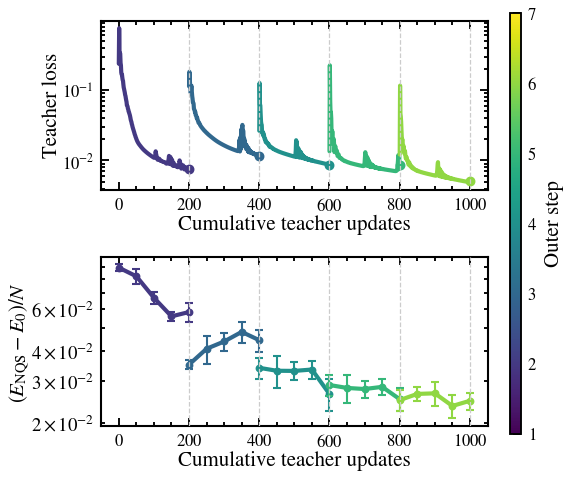

In [7]:
fig, axes   = Plotter.get_subplots(2, 1, sizex=OUTER_STEPS/2, sizey=3.3, constrained_layout=False)
get_color   = Plotter.get_colormap(values=np.linspace(0, 1, OUTER_STEPS), cmap="viridis", vmin=0, vmax=OUTER_STEPS - 1)

offset      = 0
for i, summary in enumerate(outer):
    if not summary["teacher"]["enabled"]:
        continue
    rows            = [row for row in result["teacher_history"] if row["outer"] == i]
    trace           = summary["teacher_nqs_history"]
    color           = get_color(i)
    teacher_steps   = offset + values(rows, "step")
    energy_steps    = offset + values(trace, "step")
    energy          = energy_per_site(values(trace, "energy"))
    uncertainty     = values(trace, "standard_error") / N

    Plotter.plot(axes[0], teacher_steps, values(rows, "teacher_loss"), color=color)
    Plotter.plot(axes[0], [offset + len(rows)], [summary["teacher"]["teacher_loss"]], color=color, marker="o", ls="none", ms=4)
    Plotter.plot(axes[1], energy_steps, energy, color=color, marker="o", ms=3)
    Plotter.errorbar(axes[1], energy_steps, energy, yerr=uncertainty, fmt="none", color=color, ecolor=color)
    
    offset += len(rows)
    for ax in axes:
        Plotter.vline(ax, offset, color="0.8", lw=0.6)

Plotter.set_ax_params(axes[0], xlabel="Cumulative teacher updates", ylabel="Teacher loss", yscale="log")
Plotter.set_ax_params(axes[1], xlabel="Cumulative teacher updates", ylabel=r"$(E_{\rm NQS}-E_0)/N$" if E0 is not None else r"$E_{\rm NQS}/N$", yscale='linear' if E0 is None else 'log')
Plotter.add_colorbar(fig, pos=(1.0, 0.12, 0.02, 0.85), label="Outer step", ticks=np.arange(OUTER_STEPS), ticklabels=[f"{i + 1}" for i in range(OUTER_STEPS)], mappable=get_color)

show_figure(fig, "teacher_history")



## Should we increase sampling after training the NQS?

Read these measurements together at each outer step, **before rotation**:

- Low retained NQS probability means the selected space omits appreciable weight. Increase `N_SUBSPACE` to test a larger matrix.
- If many more unique states were already observed than fit in the matrix, drawing more samples alone cannot remove that matrix-size limit.
- If few unique states were observed and coverage is poor, increase `N_SEED_SAMPLES` to test discovery. A concentrated NQS can naturally produce few unique draws.
- $E_{\rm Ritz}-E_{\rm NQS}>0$ means the sampled teacher target is energetically worse than the trained NQS before rotation. Coverage is a diagnostic; energy convergence when rerunning with larger draw and matrix budgets is the actual check. These indicators do not prove that either budget increase will improve learning.

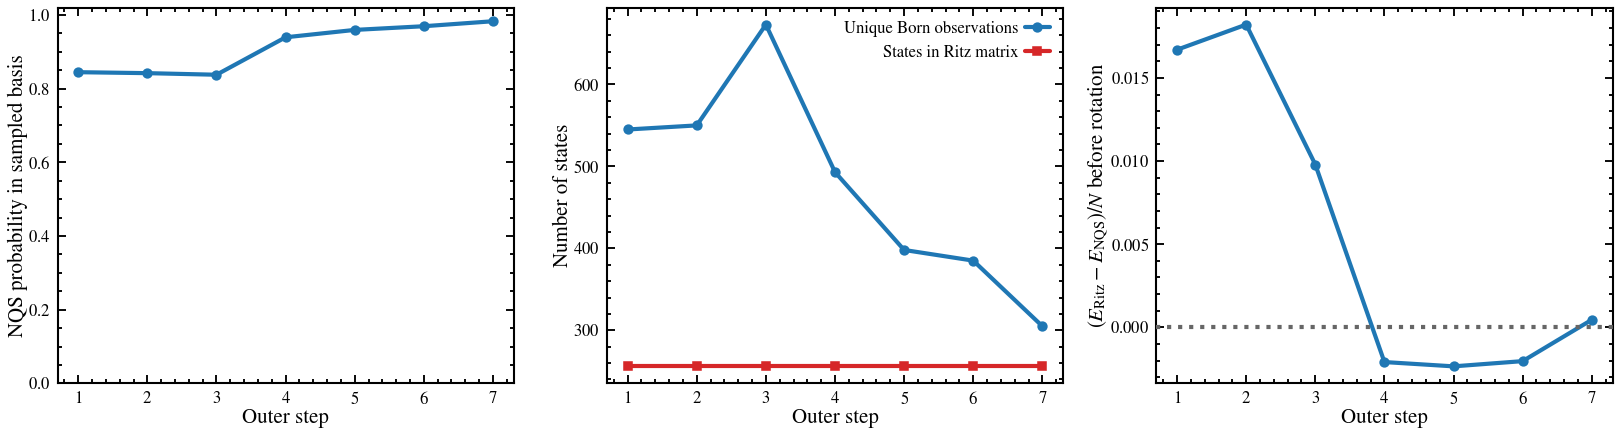

Outer | Born draws | unique | matrix | mass before | accepted | steady VMC slowdown | total seconds
    1 |       8192 |    545 |    256 |      0.8445 | True     |                 nanx |        140.30
    2 |       8192 |    550 |    256 |      0.8419 | True     |                7.82x |        354.70
    3 |       8192 |    673 |    256 |      0.8376 | True     |                1.00x |        918.59
    4 |       8192 |    493 |    256 |      0.9392 | True     |                 nanx |         93.99
    5 |       8192 |    398 |    256 |      0.9592 | True     |                1.02x |        216.86
    6 |       8192 |    385 |    256 |      0.9692 | True     |                 nanx |        107.69
    7 |       8192 |    305 |    256 |      0.9827 | True     |                 nanx |         95.96


In [8]:
k = np.arange(1, len(outer) + 1)
fig, axes = Plotter.get_subplots(1, 3, sizex=11, sizey=3.1, constrained_layout=False)
Plotter.plot(axes[0], k, [row["sampling"]["nqs_mass_before"] for row in outer], marker="o")
Plotter.set_ax_params(axes[0], xlabel="Outer step", ylabel="NQS probability in sampled basis", ylim=(0, 1.02), xticks=k)
Plotter.plot(axes[1], k, [row["sampling"]["unique_born_states"] for row in outer], marker="o", label="Unique Born observations")
Plotter.plot(axes[1], k, [row["subspace_size"] for row in outer], marker="s", label="States in Ritz matrix")
Plotter.set_ax_params(axes[1], xlabel="Outer step", ylabel="Number of states", xticks=k)
Plotter.set_legend(axes[1], frameon=False, fontsize=8)
Plotter.plot(axes[2], k, (values(outer, "ritz_energy_before_rotation") - values(outer, "energy_before_rotation")) / N, marker="o")
Plotter.hline(axes[2], 0, color="0.4", ls=":")
Plotter.set_ax_params(axes[2], xlabel="Outer step", ylabel=r"$(E_{\rm Ritz}-E_{\rm NQS})/N$ before rotation", xticks=k)
show_figure(fig, "sampling_history")

print("Outer | Born draws | unique | matrix | mass before | accepted | steady VMC slowdown | total seconds")
for row in outer:
	s = row["sampling"]
	print(f"{row['outer'] + 1:5d} | {s['born_draws']:10d} | {s['unique_born_states']:6d} | {row['subspace_size']:6d} | {s['nqs_mass_before']:11.4f} | {str(row['accepted']):8s} | {row['vmc_slowdown']:19.2f}x | {row['seconds']:13.2f}")

## Does the final Ritz energy depend strongly on the selected size?

This optional check uses the saved final production configuration set at fixed NQS parameters and accepted rotation angles. Its smaller set contains the half with the largest NQS probabilities; both projected Hamiltonians therefore describe the same rotated physical operator, and the smaller set is a subset of the larger one. The difference is a truncation diagnostic, not an energy gain from learning or proof of ground-state convergence. NQS probability mass is reported alongside it.

Enable `RUN_BASIS_CHECK` to build one full projected matrix and diagonalize its half-size principal submatrix and full matrix. This adds computation outside the production loop. For size convergence, also rerun with a larger `N_SUBSPACE` and fresh sampling; a small half-versus-full difference alone does not test omitted configurations.


In [9]:
RUN_BASIS_CHECK = False

if RUN_BASIS_CHECK:
    from src.model          import bits_to_inputs
    from src.operators      import base_hamiltonian, marshall_clifford_hamiltonian
    from src.rotation_ritz  import prepare_rotation_problem, build_rotated_subspace_hamiltonian

    # Read only the saved configurations; use the final in-memory NQS and angles.
    with np.load(OUTPUT_DIR / "recommended" / "checkpoint" / "state.npz") as checkpoint:
        full_basis = np.asarray(checkpoint["basis"], dtype=np.int8)
        
    # Check that the Ritz energies are variationally ordered when the Ritz matrix is truncated to half its size.
    n_full = len(full_basis)
    if n_full < 2:
        raise ValueError("The nested size check needs at least two configurations")
    log_psi = result["model"].apply(result["params"], bits_to_inputs(result["model"], full_basis))
    probabilities = np.exp(2 * np.real(np.asarray(log_psi)))
    half_indices = np.argsort(-probabilities, kind="stable")[:n_full // 2]

    terms = base_hamiltonian(lattice)
    if adaptive.circuit.use_marshall_clifford:
        terms = marshall_clifford_hamiltonian(lattice, terms)
    problem = prepare_rotation_problem(terms, result["gates"], full_basis, N)
    matrix = np.asarray(build_rotated_subspace_hamiltonian(problem, result["theta_star"]))
    matrix = (matrix + matrix.conj().T) / 2
    half_matrix = matrix[np.ix_(half_indices, half_indices)]
    half_energy = float(np.linalg.eigvalsh(half_matrix)[0])
    full_energy = float(np.linalg.eigvalsh(matrix)[0])
    tolerance = 1e-10 * max(1.0, abs(half_energy), abs(full_energy))
    if full_energy > half_energy + tolerance:
        raise RuntimeError("Nested Ritz energies violate the variational ordering")

    sizes = [len(half_indices), n_full]
    energies = energy_per_site([half_energy, full_energy])
    masses = [probabilities[half_indices].sum(), probabilities.sum()]
    print(f"Fixed-angle Ritz lowering per site: {(half_energy - full_energy) / N:.6g}")
    for size, energy, mass in zip(sizes, energies, masses):
        print(f"{size:6d} states | plotted energy/site={energy:+.10f} | NQS mass={mass:.6f}")

    fig, axes = Plotter.get_subplots(1, 2, sizex=8, sizey=3.3, constrained_layout=False)
    Plotter.plot(axes[0], sizes, energies, marker="o")
    energy_label = r"$(E_{\rm Ritz}-E_0)/N$" if E0 is not None else r"$E_{\rm Ritz}/N$"
    Plotter.set_ax_params(axes[0], xlabel="Nested Ritz size", ylabel=energy_label, xticks=sizes)
    Plotter.plot(axes[1], sizes, masses, marker="o")
    Plotter.set_ax_params(axes[1], xlabel="Nested Ritz size", ylabel="Retained NQS probability", xticks=sizes, ylim=(0, 1.02))
    show_figure(fig, "nested_ritz_size_check")


## Does the rotation cost improve the outer-loop energy?

Repeat the **whole staged loop** from the same seed with the same VMC and sampling budgets. Only the rotation stages differ:

- VMC only: no angles and no teacher.
- Teacher, no rotation: the unrotated Ritz target is distilled.
- Energy-only rotation: all auxiliary weights are zero.
- Recommended cost: the model-specific weights above. This is the run from the previous section.
- Recommended + participation: adds the compactness penalty $-\log(\mathrm{IPR})/\log M$.

The first figure compares accepted NQS energies after each outer step. The second reports the proposed Ritz target's IPR, cut Rényi-2 sum and projected nonstoquasticity, including rejected proposals. These runs match configured VMC counts, not total cost. Outer times include rotation, teaching, diagnostics and compilation, and later runs can reuse compiled kernels. A single seed is a diagnostic, not evidence of a general advantage.

In [84]:
def variant(**rotation_changes):
	"""Same staged schedule; only rotation-stage settings change."""
	teach = rotation_changes.pop("teach", True)
	changed = dc.replace(step, rotation=dc.replace(rotation, **rotation_changes), teacher=dc.replace(teacher, n_teacher=teacher.n_teacher if teach else 0))
	return dc.replace(adaptive, steps=staged(changed))

no_cost = dict(participation_weight=0.0, entanglement_weight=0.0, nonstoquasticity_weight=0.0)
controls = {
	"VMC only"						: variant(n_rot=0, teach=False),
	"Teacher, no rotation"			: variant(n_rot=0),
	"Energy-only rotation"			: variant(**no_cost),
	"Recommended + participation"	: variant(participation_weight=PARTICIPATION_WEIGHT),
}
runs = {}
for index, (name, config) in enumerate(controls.items()):
	log(name)
	runs[name] = run_adaptive_loop(lattice, model, config, seed=SEED, output_dir=OUTPUT_DIR / f"control_{index}")
runs = {"Recommended cost": result, **runs}

[INFO] 	->VMC only
[INFO] ===========================Adaptive-basis NQS===========================
[INFO] 	->Model: j1j2 | 4x2 | N=8 | PBC=False | seed=0
[INFO] 	->Device: cpu:0 | JAX x64=True
[INFO] 	->ARTransformer: width=16, depth=2, heads=4, mlp_ratio=2, conserve_total_sz=True
[INFO] 	->Exact ground energy: -3.641829874566 (E/N: -0.455228734321) | 0.000 s
[INFO] 	->Adaptive loop: 7 steps, 8 fixed circuit gates, 8 trainable parameters
[INFO] =============================Outer step 1/7=============================
[INFO] 	->Train NQS (250 updates) | started
[INFO] 		->[NQS] fresh init | |theta|=0.000000 | 8 gates
[INFO] 			->Hamiltonian: 48 base -> 1192 rotated -> 48 pruned terms | max connections=17
[INFO] 			->Build timings: basis=0.002 s | NetKet operator=0.005 s
[INFO] 		->NQS: minSR:sgd(mode=complex, shift=1.0e-02->1.0e-04/cosine) SPRING(0.8) | lr=0.02 | 250 updates | 256 MC samples | chunk=128


  0%|          | 0/250 [00:00<?, ?it/s]

[INFO] 		->NQS: completed 250/250 updates in 10.199 s (setup and compilation included)
[INFO] 		->[NQS] MC tail mean (pre-update observations): E=-3.478532449 | E/N=-0.434816556 | variance=0.0137208
[INFO] 	->Train NQS (250 updates) | finished in 10.208 s
[INFO] 	->Before rotation: E=-3.477627687798 | E/N=-0.434703460975
[INFO] 		->exact enumeration | variance=0.244094 | SE=0 | 0.007 s
[INFO] 		->E-E0=+0.164202 | GS fidelity=0.87576604
[INFO] 		->Seed sampling (frequency): 44 ranked seed candidates from 2240 Born draws
[INFO] 			->subspace assembled: 70 states total (0 retained + 70 seeds & connected)
[INFO] 	->Select Ritz basis: 70/70 states | NQS mass=1.000000 | 0.075 s
[INFO] 		->SQD sampling: method=frequency | Born draws=2240/2240 | unique Born states=44 | Gumbel draws=70
[INFO] 	->Rotate: 0 updates | NQS probe stride=5
[INFO] 		->Rotation weights: participation=0, entanglement=0.02, nested=0, nonstoquasticity=0.1
[INFO] 		->Angle optimization: 0 updates | angle RMS=0.000000 | opt

  0%|          | 0/100 [00:00<?, ?it/s]

[INFO] 		->NQS: completed 100/100 updates in 4.104 s (setup and compilation included)
[INFO] 		->[NQS] MC tail mean (pre-update observations): E=-3.473335441 | E/N=-0.434166930 | variance=0.00870589
[INFO] 	->Train NQS (100 updates) | finished in 4.110 s
[INFO] 	->Before rotation: E=-3.475271522114 | E/N=-0.434408940264
[INFO] 		->exact enumeration | variance=0.252969 | SE=0 | 0.005 s
[INFO] 		->E-E0=+0.166558 | GS fidelity=0.87592309
[INFO] 		->Subspace retention: kept top 7/70 states from previous Ritz basis (f_retain=0.10)
[INFO] 		->Seed sampling (frequency): 43 ranked seed candidates from 2240 Born draws
[INFO] 			->subspace assembled: 70 states total (7 retained + 63 seeds & connected)
[INFO] 	->Select Ritz basis: 70/70 states | NQS mass=1.000000 | 0.063 s
[INFO] 		->SQD sampling: method=frequency | Born draws=2240/2240 | unique Born states=43 | Gumbel draws=70
[INFO] 	->Rotate: 0 updates | NQS probe stride=5
[INFO] 		->Rotation weights: participation=0, entanglement=0.02, nested

...

[INFO] 		->Teacher probe 10/50: NQS E=-3.467943607 | SE=0
[INFO] 		->Teacher probe 20/50: NQS E=-3.558081879 | SE=0
[INFO] 		->Teacher probe 30/50: NQS E=-3.562339947 | SE=0
[INFO] 		->Teacher probe 40/50: NQS E=-3.590427052 | SE=0
[INFO] 		->Teacher loss=0.00879149 | joint KL/site=0.00603064 | conditional KL/site=0.00603064 | mass loss/site=-1.38778e-17
[INFO] 		->Subspace mass=1.000000 | phase coherence=0.994478 | phase loss=0.00276085 | 0.096 s
[INFO] 		->NQS fidelity with Ritz target=0.978773 (squared full-state overlap)
[INFO] 		->Teacher objective evaluations=51 (includes line search and final evaluation)
[INFO] 	->After teacher: E=-3.590651703842 | E/N=-0.448831462980 | dE=-0.00166116
[INFO] 		->exact enumeration | variance=0.154788 | SE=0 | 0.005 s
[INFO] 		->E-E0=+0.0511782 | GS fidelity=0.97877269
[INFO] 	->Recover VMC: 30 updates
[INFO] 		->VMC recovery: minSR:sgd(mode=complex, shift=1.0e-02->1.0e-04/cosine) SPRING(0.8) | lr=0.02 | 30 updates | 256 MC samples | chunk=128


  0%|          | 0/30 [00:00<?, ?it/s]

[INFO] 		->VMC recovery: completed 30/30 updates in 4.997 s (setup and compilation included)
[INFO] 	->After recovery: E=-3.613548548415 | E/N=-0.451693568552 | dE=-0.0228968
[INFO] 		->exact enumeration | variance=0.0731924 | SE=0 | 0.005 s
[INFO] 		->E-E0=+0.0282813 | GS fidelity=0.98581127
[INFO] 	->Proposal rejected; restored NQS and angles: NQS dE=+0.00500335 | combined SE=0 | acceptance threshold=4.15e-10
[INFO] 		->Operator cost: terms 1192 -> 1192 | max connections 115 -> 115
[INFO] 		->VMC steady update: before=0.1660 s | proposed basis=0.1647 s | slowdown=0.99x (warmup excluded)
[INFO] Outer 6: E_NQS=-3.618552 (E/N=-0.452319) Ritz=-3.641830 (E/N=-0.455229) +PT2=-3.641830 (E/N=-0.455229)
[INFO] 	->##################Outer 6 timing##################
[INFO] 		->|--------------------|----------------|
[INFO] 		->| Phase              |   Duration (s) |
[INFO] 		->|--------------------|----------------|
[INFO] 		->| Train NQS          |         16.872 |
[INFO] 		->| SQD basis       

  0%|          | 0/150 [00:00<?, ?it/s]

[INFO] 		->NQS: completed 150/150 updates in 25.443 s (setup and compilation included)
[INFO] 		->[NQS] MC tail mean (pre-update observations): E=-3.620858368 | E/N=-0.452607296 | variance=0.0037841
[INFO] 	->Train NQS (150 updates) | finished in 25.458 s
[INFO] 	->Before rotation: E=-3.620360240579 | E/N=-0.452545030072
[INFO] 		->exact enumeration | variance=0.0559702 | SE=0 | 0.009 s
[INFO] 		->E-E0=+0.0214696 | GS fidelity=0.98899376
[INFO] 		->Subspace retention: kept top 7/70 states from previous Ritz basis (f_retain=0.10)
[INFO] 		->Seed sampling (frequency): 50 ranked seed candidates from 2240 Born draws
[INFO] 			->subspace assembled: 70 states total (7 retained + 63 seeds & connected)
[INFO] 	->Select Ritz basis: 70/70 states | NQS mass=1.000000 | 0.103 s
[INFO] 		->SQD sampling: method=frequency | Born draws=2240/2240 | unique Born states=50 | Gumbel draws=0
[INFO] 	->Rotate: 0 updates | NQS probe stride=5
[INFO] 		->Rotation weights: participation=0.05, entanglement=0.02, n

Recommended cost             | final E/N=+4.97727e-04 | accepted=4/7 | outer time=141.1 s
VMC only                     | final E/N=+2.03678e-02 | accepted=7/7 | outer time=44.0 s
Teacher, no rotation         | final E/N=+4.13076e-04 | accepted=6/7 | outer time=44.4 s
Energy-only rotation         | final E/N=+4.13076e-04 | accepted=6/7 | outer time=48.6 s
Recommended + participation  | final E/N=+2.68370e-03 | accepted=5/7 | outer time=141.8 s


/var/folders/7h/4tmv99_x2djdm97ys2h7mh5m0000gs/T/ipykernel_20358/3221727541.py:62: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


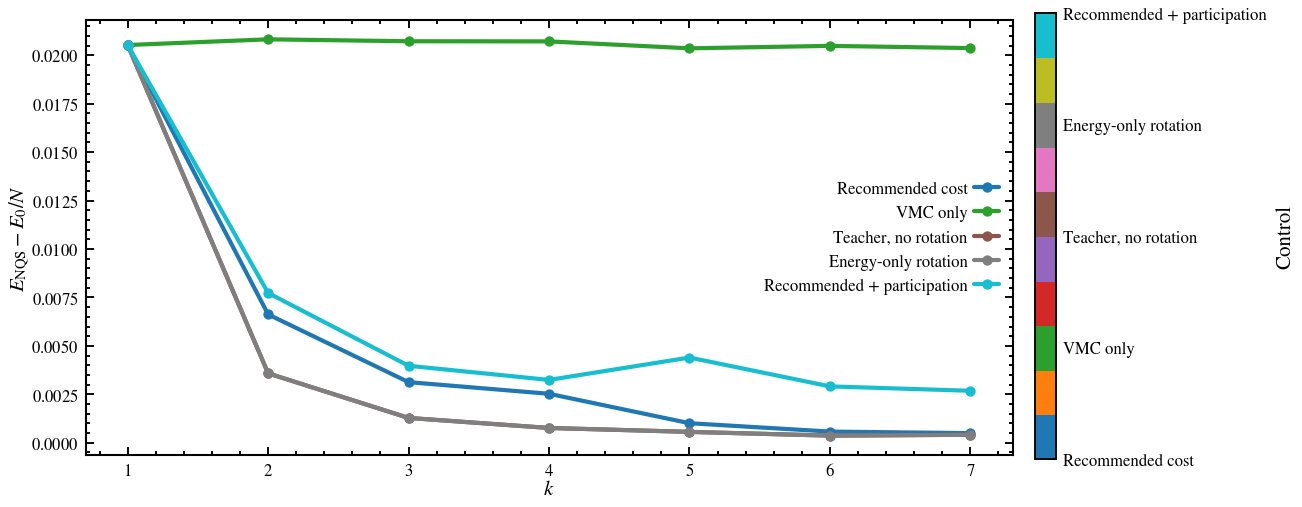

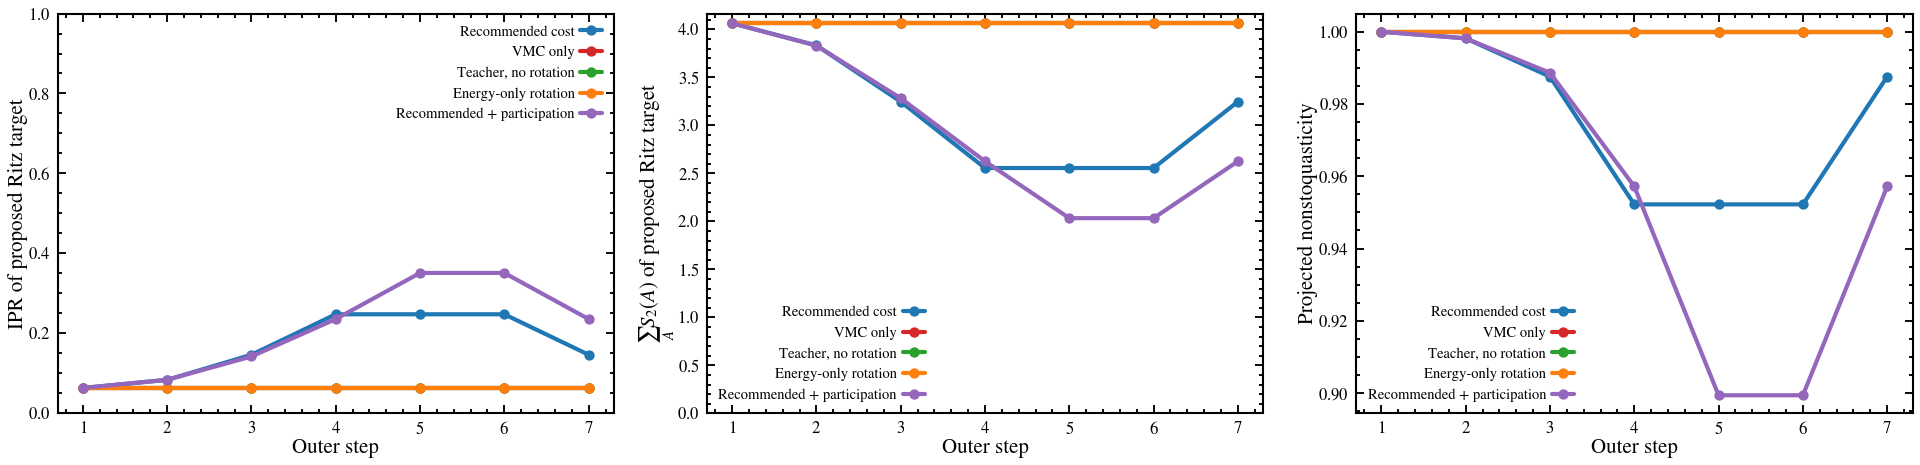

In [87]:
k       = np.arange(1, N_OUTER + 1)
fig, ax = Plotter.get_subplots(1, 1, sizex=7, sizey=3.5, constrained_layout=False)
get_c   = Plotter.get_colormap(values=np.linspace(0, 1, len(runs)), cmap="tab10", vmin=0, vmax=len(runs) - 1)

for index, (name, run) in enumerate(runs.items()):
    rows    = run["outer_history"]
    energy  = energy_per_site(values(rows, "energy"))
    Plotter.plot(ax, k, energy, color=get_c(index), marker="o", label=name)
    print(f"{name:28s} | final E/N={energy[-1]:+.5e} | accepted={sum(row['accepted'] for row in rows)}/{len(rows)} | outer time={sum(row['seconds'] for row in rows):.1f} s")
    
Plotter.set_ax_params(ax, xlabel="$k$", ylabel=r"$E_{\rm NQS}-E_0/N$" if E0 is not None else r"$E_{\rm NQS}/N$", xticks=k)
Plotter.set_legend(ax, frameon=False, fontsize=8)
Plotter.add_colorbar(fig, pos=(1.0, 0.12, 0.02, 0.85), label="Control", ticks=np.arange(len(runs)), ticklabels=list(runs.keys()), mappable=get_c)
show_figure(fig, "outer_energy_comparison")

fig, axes = Plotter.get_subplots(1, 3, sizex=13, sizey=3.3, constrained_layout=False)
for index, (name, run) in enumerate(runs.items()):
    rows = [row["proposal_ritz_metrics"] for row in run["outer_history"]]
    Plotter.plot(axes[0], k, np.exp(-values(rows, "ritz_participation_entropy")), color=f"C{index}", marker="o", label=name)
    Plotter.plot(axes[1], k, values(rows, "ritz_renyi2_sum"), color=f"C{index}", marker="o", label=name)
    Plotter.plot(axes[2], k, values(rows, "ritz_nonstoquasticity"), color=f"C{index}", marker="o", label=name)
Plotter.set_ax_params(axes[0], xlabel="Outer step", ylabel="IPR of proposed Ritz target", ylim=(0, 1), xticks=k)
Plotter.set_ax_params(axes[1], xlabel="Outer step", ylabel=r"$\sum_A S_2(A)$ of proposed Ritz target", xticks=k)
Plotter.set_ax_params(axes[2], xlabel="Outer step", ylabel="Projected nonstoquasticity", xticks=k)
axes[1].set_ylim(bottom=0)
for ax in axes:
    Plotter.set_legend(ax, frameon=False, fontsize=7)
show_figure(fig, "representation_history")


## Optional: spinful Hubbard with spatial-orbital rotations

Set `RUN_FERMIONIC=True` after installing the `fermion` extra. The loop rotates spatial orbitals identically for both spins and keeps both particle numbers fixed. `QUICK` selects the open 2 x 2 lattice (36 determinants, exact oracle) or the open 3 x 2 lattice (400 determinants, Monte Carlo acceptance).

Here the orbital basis itself is the physics. Localized orbitals suit large $U/t$; delocalized orbitals suit small $U/t$. The rotation cost penalizes entanglement along the **model mode order** (`entanglement_order="model"`), because that is the order the autoregressive conditionals see. A small participation weight favors compact determinant expansions. Angles are optimized by L-BFGS on the selected determinant space, with optional basin hopping (`n_basin`).

In [ ]:
RUN_FERMIONIC = False

if RUN_FERMIONIC:
	from src.fermionic import HubbardConfig, run_fermionic_loop

	hubbard		= HubbardConfig(Lx=2 if QUICK else 3, Ly=2, pbc=False, t=1.0, U=4.0)
	f_model		= ModelConfig(width=8 if QUICK else 16, depth=1 if QUICK else 2, heads=2, mlp_ratio=2)
	f_train		= TrainConfig(n_nqs=100 if QUICK else 300, n_samples=128 if QUICK else 512, learning_rate=0.01, use_sr=False, optimizer="adam")
	f_rotation	= RotationConfig(n_rot=40, n_basin=0 if QUICK else 2, n_subspace=24 if QUICK else 96, sampling="gumbel", participation_weight=0.05, entanglement_weight=0.1, entanglement_order="model")
	f_step		= AdaptiveStep(train=f_train, rotation=f_rotation, teacher=TeacherConfig(n_teacher=100, phase_weight=0.5), n_recovery=50)
	f_warm		= dc.replace(f_step, train=dc.replace(f_train, n_nqs=N_WARM), rotation=dc.replace(f_rotation, n_rot=0, n_basin=0), teacher=dc.replace(f_step.teacher, n_teacher=0), n_recovery=0)
	f_config	= AdaptiveConfig(circuit=CircuitConfig(n_layers=2), steps=(f_warm,) + (f_step,) * N_ROTATE, display="plain")
	fermions	= run_fermionic_loop(hubbard, f_model, f_config, seed=SEED, output_dir=OUTPUT_DIR / "hubbard")

	rows, rotations = fermions["outer_history"], fermions["rotation_history"]
	fk = np.arange(1, len(rows) + 1)
	fig, axes = Plotter.get_subplots(1, 2, sizex=10, sizey=3.3, constrained_layout=False)
	exact_fermion_energy = fermions["exact_energy"]
	Plotter.plot(axes[0], fk, energy_per_site(values(rows, "energy_before_rotation"), hubbard.n_sites, exact_fermion_energy), marker="o", label="Before rotation")
	Plotter.plot(axes[0], fk, energy_per_site(values(rows, "energy"), hubbard.n_sites, exact_fermion_energy), marker="s", label="Accepted")
	if exact_fermion_energy is not None:
		Plotter.hline(axes[0], 0, color="0.4", ls=":", label="Exact ground energy")
	fermion_energy_label = r"$(E_{\rm NQS}-E_0)/N$" if exact_fermion_energy is not None else r"$E_{\rm NQS}/N$"
	Plotter.set_ax_params(axes[0], xlabel="Outer step", ylabel=fermion_energy_label, xticks=fk)
	rk = [row["outer"] + 1 for row in rotations]
	Plotter.plot(axes[1], rk, values(rotations, "objective_before"), marker="o", label="Objective before")
	Plotter.plot(axes[1], rk, values(rotations, "objective"), marker="s", label="Objective after")
	Plotter.set_ax_params(axes[1], xlabel="Outer step", ylabel="Orbital rotation objective", xticks=fk)
	for ax in axes:
		Plotter.set_legend(ax, frameon=False, fontsize=8)
	show_figure(fig, "hubbard_history")